# Dapur Domino — Eksplorasi Data, Desain Skenario, & Evaluasi Pemodelan Data Science

**Melacak Efek Domino Harga Pangan Nasional (PIHPS Bank Indonesia) × Jaringan Asosiasi Bahan Masakan Nusantara (`69.915` Resep)**

Notebook ini mendokumentasikan perjalanan lengkap proyek *Data Science* secara *end-to-end* dengan bahasa yang jelas dan bukti terukur dari artefak nyata proyek — berjalan **100% lokal (`<= 8 GB RAM`, `seed = 42`)**, bebas kebocoran data masa depan, dan melaporkan hasil positif maupun negatif secara jujur.

### Daftar Isi
1. **Perumusan Masalah & Target Terukur**
2. **Telaah Data Harga & Resep Nusantara (EDA)**
3. **Validasi Mutu Data, Stasioneritas 2 Pintu, & Segel Amplop Ujian**
4. **Pembersihan Data & Konstruksi 11 Fitur Bebas Kebocoran**
5. **Adu 8 Skenario Simulasi & Pembangunan Model (Domino + Kuliner)**
6. **Ujian Dunia Nyata (`296` Hari Uji), Autopsi Error, & Jembatan Sadar-Harga**
7. **Tinjauan Akhir Model (*Go / Fallback*), Batasan Jujur, & Rencana Iterasi Ke-2**

---
## 1. Perumusan Masalah & Target Terukur

Sebelum menyentuh angka, keluhan nyata pembeli pasar, warung kuliner, dan juru masak rumahan diterjemahkan menjadi **4 sasaran usaha** dan **7 target teknis** beserta pembanding polos (*baseline*) agar setiap klaim kemajuan bisa diuji secara adil.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dapur_domino.cleaning.ingredients import load_synonym_map, normalize_ingredient_line

plt.rcParams.update({
    "figure.facecolor": "#FFFBF2",
    "axes.facecolor": "#FFFBF2",
    "axes.edgecolor": "#D9CBB6",
    "axes.grid": True,
    "grid.color": "#EADFD0",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "font.size": 10,
})

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ANALYSIS_DIR = REPO_ROOT / "artifacts" / "analysis"
RUNS_DIR = REPO_ROOT / "artifacts" / "runs"
M1_DIR = sorted(RUNS_DIR.glob("m1_*"))[-1]
M2_DIR = sorted(RUNS_DIR.glob("m2_*"))[-1]
M3_DIR = sorted(RUNS_DIR.glob("m3_*"))[-1]
M4_DIR = sorted(RUNS_DIR.glob("m4_*"))[-1]

business_df = pd.read_csv(ANALYSIS_DIR / "business_objectives.csv")
technical_df = pd.read_csv(ANALYSIS_DIR / "technical_objectives.csv")

print(f"Artefak run aktif: M1={M1_DIR.name}, M2={M2_DIR.name}, M3={M3_DIR.name}, M4={M4_DIR.name}")
display(business_df[["objective_id", "stakeholder", "business_problem", "kpi_business"]])
display(technical_df[["tech_objective_id", "ds_problem_type", "metric_name", "target_threshold", "measured_result", "status"]])

Artefak run aktif: M1=m1_20261118T080609Z, M2=m2_20261118T080707Z, M3=m3_20261118T070540Z, M4=m4_20261118T080802Z


,objective_id,stakeholder,business_problem,kpi_business
0,BO-1,Rumah Tangga & Konsumen Harian,"Saat harga komoditas bumbu/pangan melonjak, ko...",Cakupan bahan terekomendasi terhadap total pem...
1,BO-2,Pelaku UMKM Kuliner & Warung Makan,Kenaikan harga bahan pokok merambat antar-komo...,Tingkat temuan palsu (false discovery) jaringa...
2,BO-3,Pengguna Dapur (Optimasi Bahan Tersedia),Bahan sisa di kulkas sering terbuang karena pe...,Akurasi Top-5 prediksi bahan pelengkap mengala...
3,BO-4,Reviewer Teknis & Audit Riset Data Science,Banyak eksperimen sains data mencampur data la...,"100% artefak terverifikasi SHA-256, 0% kebocor..."


,tech_objective_id,ds_problem_type,metric_name,target_threshold,measured_result,status
0,TDO-1,NLP Rule-Based & Dictionary Text Normalization,VP1 Clean Normalization Accuracy (n=300 eval s...,>= 90.0%,90.33% (271/300),TERCAPAI (VERIFIED)
1,TDO-2,Graph Association (NPMI/Louvain) & Conditional...,VP2 Hide-One-Ingredient Top-5 Accuracy vs Popu...,> Popularity baseline with disjoint 95% Wilson CI,45.50% vs 40.88%,TERCAPAI (VERIFIED)
2,TDO-3,Skip-Gram Word2Vec Embedding & Complement-Pena...,VP3 Substitution Recall@5 on 25 Culinary Refer...,Dilaporkan secara jujur beserta analisis error,24.0% (6/25),TERUKUR & DIEVALUASI JUJUR
3,TDO-4,Time-Series Log-Return Stationarity (ADF + KPSS),VP4 Joint Stationarity Pass Rate (ADF p<0.05 &...,Mayoritas (>85%) seri lulus uji ganda,"Nas 90.0%, Prov 98.24%, Kota 98.00%",TERCAPAI (VERIFIED)
4,TDO-5,Granger Causality Network + BH-FDR + Permutati...,VP5 False Edge Rate (20x Circular Shift) & VP7...,VP5 <= 5.0% FDR alpha; VP7 dilaporkan,VP5=3.44% (<=5%); VP7=100% (50/50 bertahan),TERCAPAI (VERIFIED)
5,TDO-6,Out-of-Sample Walk-Forward ARX(5) Ridge vs AR(...,VP6 Out-of-Sample RMSE & Diebold-Mariano Test ...,Validasi selektif per komoditas (tanpa klaim b...,"2/10 lolos penuh di Raw (Daging Sapi, Minyak G...",TERCAPAI SELEKTIF (VERIFIED)
6,TDO-7,Multi-Criteria Price-Aware Substitution Scoring,FR-C4 Recipe Mention Coverage & Unmapped Honesty,Cakupan kemunculan resep >= 25%; 0 harga fiktif,27.74% kemunculan resep (217.380/783.564),TERCAPAI (VERIFIED)


---
## 2. Telaah Data Harga & Resep Nusantara (EDA)

Pada tahap ini kita memeriksa watak **1.141.526 catatan harga harian PIHPS Bank Indonesia** (`796` hari pasar aktif, `Nov 2023 – Nov 2026`) serta **69.915 resep Nusantara** (`66.419` resep latih & `3.496` resep uji):
* **Mengapa harga Rupiah mentah tidak bisa dibandingkan langsung?** Harga Cabai Rawit bergoyang hingga **20,80%** (hampir **7× lipat** lebih liar daripada Beras di **2,96%**), sementara Daging Sapi mahal per kilo (~Rp 138,7 ribu) namun goyangannya amat jinak (**3,45%**).
* **Kesetaraan latih vs uji & Hukum Zipf Resep:** Rata-rata bahan per resep hampir kembar (`13,02` vs `13,06`, median sama `13`), membuktikan soal ujian adil. Hanya **10 bumbu teratas** sudah menyumbang **40,64%** catatan dapur, dan **50 bumbu inti** menguasai **80,40%**.

,commodity_name,n_days,mean_idr,min_idr,max_idr,cv_pct,return_skewness
9,Beras,796,15597.86,13750.0,16550.0,2.96,0.6953
8,Gula Pasir,796,18855.59,16450.0,20150.0,3.37,0.4473
7,Daging Sapi,796,138706.72,127900.0,149900.0,3.45,-1.8647
6,Telur Ayam,796,30471.98,26400.0,33700.0,3.89,-1.5935
5,Daging Ayam,796,38049.31,30700.0,43900.0,5.85,2.0749
4,Bawang Putih,796,41839.45,37400.0,48100.0,6.25,2.0566
3,Minyak Goreng,796,20713.76,18100.0,23150.0,6.72,1.1080
2,Bawang Merah,796,42186.12,27250.0,58100.0,16.17,4.1677
1,Cabai Merah,796,54101.26,30950.0,85100.0,19.95,0.9644
0,Cabai Rawit,796,61034.99,38800.0,95700.0,20.80,1.0393


,aspect,count,mean,median,p95,note
0,"Jumlah Bahan Bersih per Resep (Train, n=66.419)",66419,13.0200,13.0000,22.00,Rata-rata resep Nusantara memakai ~13 bahan un...
1,"Jumlah Bahan Bersih per Resep (Eval, n=3.496)",3496,13.0600,13.0000,22.00,Distribusi split Eval identik dengan Train (ti...
2,Frekuensi Resep per Bahan di Kosakata (n=1.334...,1334,587.3800,46.0000,1341.20,Distribusi power-law (Zipf): Top-10 bahan meny...
3,Bobot Asosiasi NPMI pada Graf Bahan (n=11.938 ...,11938,0.1518,0.1139,0.38,"Pasangan bahan dengan NPMI >= 0,05 dan ko-okur..."
4,Ukuran Komunitas Rasa Louvain (n=82 komunitas),82,16.2700,1.0000,100.60,"Terbentuk klaster bumbu dasar, kue/baking, rem..."


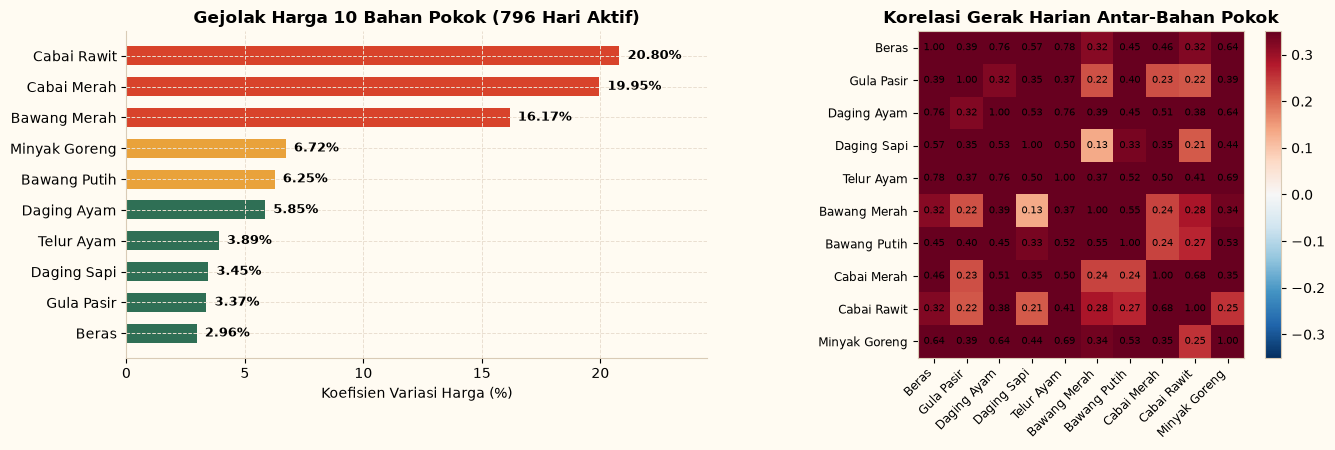

In [2]:
eda_prices = pd.read_csv(ANALYSIS_DIR / "eda_prices_stats.csv").sort_values("cv_pct", ascending=True)
eda_corr = pd.read_csv(ANALYSIS_DIR / "eda_returns_corr.csv").set_index("commodity_name")
eda_recipes = pd.read_csv(ANALYSIS_DIR / "eda_recipes_stats.csv")

display(eda_prices[["commodity_name", "n_days", "mean_idr", "min_idr", "max_idr", "cv_pct", "return_skewness"]])
display(eda_recipes[["aspect", "count", "mean", "median", "p95", "note"]])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.1, 1.0]})

colors = ["#D8432B" if v >= 15 else ("#E9A23B" if v >= 6 else "#2F6F55") for v in eda_prices["cv_pct"]]
bars = axes[0].barh(eda_prices["commodity_name"], eda_prices["cv_pct"], color=colors, height=0.62)
for b, val in zip(bars, eda_prices["cv_pct"]):
    axes[0].text(b.get_width() + 0.35, b.get_y() + b.get_height() / 2, f"{val:.2f}%", va="center", fontweight="bold", fontsize=9)
axes[0].set_xlim(0, 24.5)
axes[0].set_xlabel("Koefisien Variasi Harga (%)")
axes[0].set_title("Gejolak Harga 10 Bahan Pokok (796 Hari Aktif)", fontweight="bold")
axes[0].spines[["top", "right"]].set_visible(False)

im = axes[1].imshow(eda_corr.values, cmap="RdBu_r", vmin=-0.35, vmax=0.35)
axes[1].set_xticks(range(len(eda_corr.columns)))
axes[1].set_xticklabels(eda_corr.columns, rotation=45, ha="right", fontsize=8.5)
axes[1].set_yticks(range(len(eda_corr.index)))
axes[1].set_yticklabels(eda_corr.index, fontsize=8.5)
for r_i in range(len(eda_corr.index)):
    for c_i in range(len(eda_corr.columns)):
        axes[1].text(c_i, r_i, f"{eda_corr.values[r_i, c_i]:.2f}", ha="center", va="center", fontsize=7)
axes[1].set_title("Korelasi Gerak Harian Antar-Bahan Pokok", fontweight="bold")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

---
## 3. Validasi Mutu Data, Uji Keamanan 2 Pintu (`ADF + KPSS`), & Segel Amplop Ujian

Dua harga yang sama-sama merangkak naik karena inflasi mudah menipu model seolah saling memicu. Karena itu data harga diubah menjadi **persen gerak harian (`log-return`)** dan wajib lulus dua uji keamanan sekaligus (**ADF** menolak tren acak & **KPSS** memastikan permukaan datar). Sementara rentang **796 hari** disekat ketat: **`[0:400]` Sub-latih**, **`[400:500]` Simulasi Validasi**, dan **`[500:796]` (`296` hari)** disegel rapat sebagai amplop ujian akhir.

,validation_check,scope,before_or_raw,validated_result,validation_status,action_taken
0,Integritas Kriptografis Data Mentah (SHA-256 M...,379 file mentah di data/raw/,379 file tercatat,0 error integritas (100% cocok),VALID,Setiap file diverifikasi ukuran byte & SHA-256...
1,Kelengkapan Kalender Hari Kerja & Hari Libur N...,Panel Harga PIHPS (2023-11-01 s.d. 2026-11-18),804 hari kerja Senin-Jumat,796 hari pasar buka (8 hari libur >=90% kosong...,VALID,Akhir pekan tidak diimputasi; celah pendek <=3...
2,Kelengkapan Seri Harga per Wilayah (Batas Miss...,"Nasional (10), Provinsi (340), Kota/Kab (1.099...",Total 1.449 seri komoditas x wilayah,"Nasional 10/10, Provinsi 340/340, Kota 1049/10...",VALID,50 seri kota yang jarang melapor dikeluarkan a...
3,Audit Anomali Lonjakan Harian (|ln(P_t/P_{t-1}...,1.399 seri harga bersih x 796 hari kerja,Pemeriksaan lonjakan ekstrem > ~91% sehari,"Nasional: 0 titik, Provinsi: 9 titik, Kota: 66...",VALID (TERCATAT),Dicatat di outlier_audit_*.csv tanpa memalsuka...
4,Validasi Stasioneritas Deret Waktu (Uji Ganda ...,Harga Mentah (Level) vs Log-Return pada 1.399 ...,"Level lulus ganda: Nas 0/10, Prov 68/340, Kota...","Log-return lulus ganda: Nas 9/10 (90.0%), Prov...",VALID,Pemodelan Granger & ARX wajib memakai log-retu...
5,Audit Kualitas Normalisasi Teks Bahan (VP1),300 baris acak dari eval.parquet,"Teks mentah berisi angka, satuan, kurung, sing...",271/300 (90.33%) bersih sempurna (>= ambang 90%),VALID,29 baris residu didokumentasikan untuk perbaik...


,data_object,selection_decision,volume_selected,rationale
0,Sumber Harga Harian (D1: PIHPS Bank Indonesia),DIPILIH (Utama),1.141.526 observasi (10 komoditas x 796 hari k...,Satu-satunya sumber resmi harian yang mencakup...
1,Sumber Indeks Bulanan (D2: Open Data Bapanas),PEMBANDING (Tidak digabung ke deret harian),130 baris sampel indikator bulanan,Berfrekuensi bulanan sehingga tidak cocok untu...
2,Seri Kota/Kabupaten dengan Missingness > 20%,DIEKSKLUSI (50 dari 1.099 seri kota),1049 seri kota dipertahankan,Mencegah distorsi autokorelasi akibat forward-...
3,Pembagian Waktu Deret Harga (Chronological Split),"Train [0:400], Val [400:500], Test [500:796]",500 hari pengembangan (400 sub-train + 100 val...,Menjaga urutan kausal waktu (0% look-ahead bia...
4,Korpus Resep Masakan (D3: junwatu/indonesian-r...,DIPILIH (Train 66.419 + Eval 3.496 resep),69.915 resep (897.519 baris bahan mentah),"Ukuran besar, berbahasa Indonesia asli, dan su..."
5,Kosakata Bahan Resep (Filter min_ingredient_fr...,DIPILIH 1.334 bahan kanonik,"Mencakup 783,564 dari 852,568 baris (91.91% to...",Memangkas salah ketik langka (<20 resep) sambi...


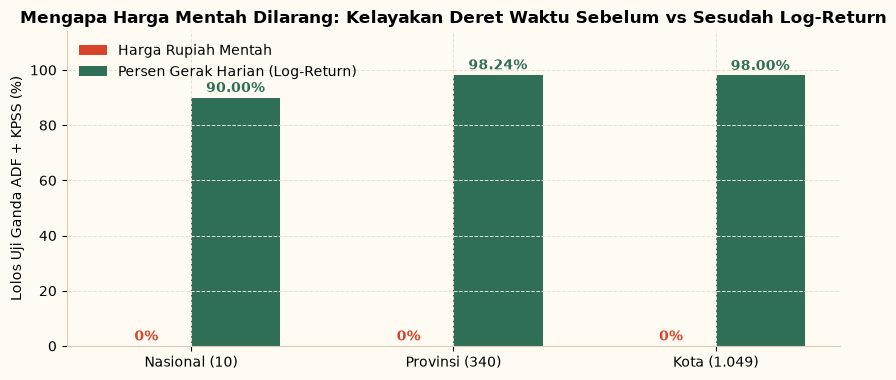

In [3]:
val_df = pd.read_csv(ANALYSIS_DIR / "data_validation_report.csv")
sel_df = pd.read_csv(ANALYSIS_DIR / "data_selection_matrix.csv")
display(val_df)
display(sel_df)

levels = ["Nasional (10)", "Provinsi (340)", "Kota (1.049)"]
raw_pass = [0.0, 0.0, 0.0]
ret_pass = [90.0, 98.24, 98.00]

x = np.arange(len(levels))
w = 0.34
fig, ax = plt.subplots(figsize=(8.6, 3.9))
b1 = ax.bar(x - w/2, raw_pass, width=w, label="Harga Rupiah Mentah", color="#D8432B")
b2 = ax.bar(x + w/2, ret_pass, width=w, label="Persen Gerak Harian (Log-Return)", color="#2F6F55")
for b in b1:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 2, "0%", ha="center", fontweight="bold", color="#D8432B")
for b, v in zip(b2, ret_pass):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{v:.2f}%", ha="center", fontweight="bold", color="#2F6F55")
ax.set_xticks(x)
ax.set_xticklabels(levels)
ax.set_ylim(0, 114)
ax.set_ylabel("Lolos Uji Ganda ADF + KPSS (%)")
ax.set_title("Mengapa Harga Mentah Dilarang: Kelayakan Deret Waktu Sebelum vs Sesudah Log-Return", fontweight="bold")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

---
## 4. Pembersihan Data & Konstruksi 11 Fitur Bebas Kebocoran

Di jalur harga, `8` hari libur nasional (`>= 90%` seri kosong) dan `50` seri kota yang bolong `> 20%` dibuang, lalu kekosongan pendek ditambal maksimal `3` hari kerja. Di jalur resep, `852.568` baris bumbu kotor dibersihkan dengan penghapus takaran, pemisah `'garam gula'`, dan **236 kamus sinonim** (`271/300 = 90,33%` bersih pada audit manual). Di bawah ini juga dijalankan langsung fungsi pembersih asli proyek pada contoh baris resep kotor.

In [4]:
cln_df = pd.read_csv(ANALYSIS_DIR / "data_cleaning_audit.csv")
fea_df = pd.read_csv(ANALYSIS_DIR / "feature_engineering_audit.csv")
display(cln_df)
display(fea_df)

synonyms = load_synonym_map(REPO_ROOT / "data" / "external" / "ingredient_synonyms.csv")
sample_lines = [
    "1/2 kol (3 ribu) (potong)",
    "3 siung bawang putih iris",
    "1 sdt garam gula",
    "3 lbr daun jeruk, buang tulang daunnya, sobek sobek",
    "2 sdm baput & bamer halus",
]
demo_clean = pd.DataFrame([
    {"teks_mentah": line, "hasil_normalisasi": normalize_ingredient_line(line, synonyms)}
    for line in sample_lines
])
display(demo_clean)

,cleaning_stage,raw_input_issue,cleaning_rule,output_impact
0,1. Parsing Angka & Tanggal PIHPS (ingest/pihps...,"Harga berformat string '58,450' atau '-', spas...","Hapus koma ribuan, konversi '-' ke NaN, strip ...","1,141,526 record bersih terstruktur di long pa..."
1,2. Penyelarasan Hari Kerja & Hari Libur (clean...,Hari libur nasional seluruh pasar kosong (NaN ...,Reindex ke frekuensi 'B' (Senin-Jumat) & drop ...,Dari 804 hari kerja menjadi 796 hari pasar buka.
2,3. Penanganan Missing Value Terbatas (cleaning...,Celah 1-3 hari pada pelaporan kota & seri pasi...,"Drop seri missing >20%, lalu forward-fill maks...",1049 seri kota bersih; 50 seri pasif dibuang.
3,4. Pembersihan Kuantitas & Satuan Resep (clean...,Teks seperti '250 gr dada ayam fillet (potong ...,"Hapus isi kurung, angka/pecahan, 80+ satuan da...","Memproses 852,568 baris latih & 44,951 baris uji."
4,5. Pemisahan Bahan Majemuk & Kamus Sinonim (in...,"Baris gabungan 'garam dan gula secukupnya', 'b...","Split konjungsi (, / & dan atau) + pemetaan 23...",Menghasilkan 1.334 bahan kanonik dengan akuras...


,feature_group,mathematical_formula,dimensionality,purpose_and_leakage_control
0,Log-Return Harian (r_t),r_t = ln(P_t / P_{t-1}),"796 hari x (10 Nas, 340 Prov, 1.049 Kota)",Menstasionerkan deret harga dan menyamakan ska...
1,Matriks Desain Musiman & Hari Raya (X_cal),"[1, DOW_1..4, sin(2pi*k*d/365.25), cos(2pi*k*d...",796 hari x 11 fitur eksogen,Koefisien OLS beta di-fit HANYA pada data lati...
2,Matriks Lag Autoregressive Exogenous ARX(p),"[1, y_{t-1}..y_{t-p}, x^{(1)}_{t-1}..x^{(m)}_{...",1 + p*(1 + m_triggers) fitur per komoditas,Hanya memakai nilai masa lalu (t-1 s.d. t-p) u...
3,"Bobot Graf Ko-okurensi Bahan (PMI, NPMI, Lift)","NPMI(a,b) = log(P(a,b)/(P(a)P(b))) / (-log P(a...","1.334 simpul, 11.938 sisi berarah/tak-berarah",Dihitung murni dari 66.419 resep train.parquet...
4,Vektor Embedding Bahan Word2Vec & Skor Substitusi,"sub(a,b) = cos(v_a, v_b) * (1 - max(0, NPMI(a,...",1.334 bahan x 64 dimensi vektor laten,Menangkap kesamaan peran kuliner (cosine tingg...
5,Skor Stabilitas Harga 30 Hari & Skor Hibrida,"S_price = exp(-max(0, dP_30d)) * exp(-5 * vol_...",10 komoditas x 140 wilayah (Nasional/Prov/Kota),"Bobot 0,6 / 0,4 dikunci di konfigurasi sebelum..."


,teks_mentah,hasil_normalisasi
0,1/2 kol (3 ribu) (potong),[kubis]
1,3 siung bawang putih iris,[bawang putih]
2,1 sdt garam gula,"[garam, gula pasir]"
3,"3 lbr daun jeruk, buang tulang daunnya, sobek ...","[daun jeruk, buang tulang daunnya, sobek]"
4,2 sdm baput & bamer halus,"[bawang putih, bawang merah]"


---
## 5. Adu 8 Skenario Simulasi (`[400:500]`) & Pembangunan Model Domino + Kuliner

Sebelum menyentuh `296` hari ujian, `8` setelan model harga diadu di ruang simulasi `[400:500]`. Terlihat jelas jebakan **overfitting** pada `S03` (`lag=5`, nyaris tanpa rem `alpha=0,001`) yang anjlok **`-6,64%`** terhadap *Naive*. Begitu dipasangi **rem Ridge (`alpha=1,0`)** dan efek kalender/Lebaran dikupas (`S08`), model berbalik unggul di kedua pembanding (`+4,16%` vs `AR` & `+1,59%` vs `Naive`).

,scenario_id,lag_order,ridge_alpha,mean_skill_vs_ar_pct,mean_skill_vs_naive_pct,scenario_description
0,S01,1,1.000,-1.264,-4.195,AR(1) vs Domino ARX(1) | Ridge alpha=1.0 (Raw)
1,S02,3,1.000,5.299,-2.000,AR(3) vs Domino ARX(3) | Ridge alpha=1.0 (Raw)
2,S03,5,0.001,1.060,-6.642,AR(5) vs Domino ARX(5) | OLS Nyaris Tanpa Regu...
3,S04,5,0.100,5.978,-0.679,AR(5) vs Domino ARX(5) | Ridge Ringan alpha=0....
4,S05,5,1.000,4.656,-1.605,AR(5) vs Domino ARX(5) | Ridge Standar alpha=1...
5,S06,5,10.000,3.591,-2.516,AR(5) vs Domino ARX(5) | Ridge Kuat alpha=10.0...
6,S07,3,1.000,4.432,1.004,AR(3) vs Domino ARX(3) | Ridge alpha=1.0 (Seas...
7,S08,5,1.000,4.164,1.586,AR(5) vs Domino ARX(5) | Ridge Standar alpha=1...


,model_id,model_name,duration_sec,peak_ram_mb
0,MDL-B1,Panel Log-Return & Dual Stationarity Screener ...,50.80,796.10
1,MDL-B2,Calendar-Fourier-Holiday OLS Seasonal Residual...,54.17,202.10
2,MDL-B3,Directed Granger Causality Network + Benjamini...,54.17,202.10
3,MDL-B4,Expanding-Window Domino ARX(5) Ridge Forecaster,54.17,202.10
4,MDL-A1,NPMI Co-occurrence Graph & Louvain Flavor Comm...,52.23,313.57
5,MDL-A2,Conditional Co-occurrence PMI Complement Recom...,52.23,313.57
6,MDL-A3,Skip-Gram Word2Vec + Complement-Penalized Subs...,52.23,313.57
7,MDL-C1,Price-Aware Hybrid Substitution Scorer,0.13,92.90


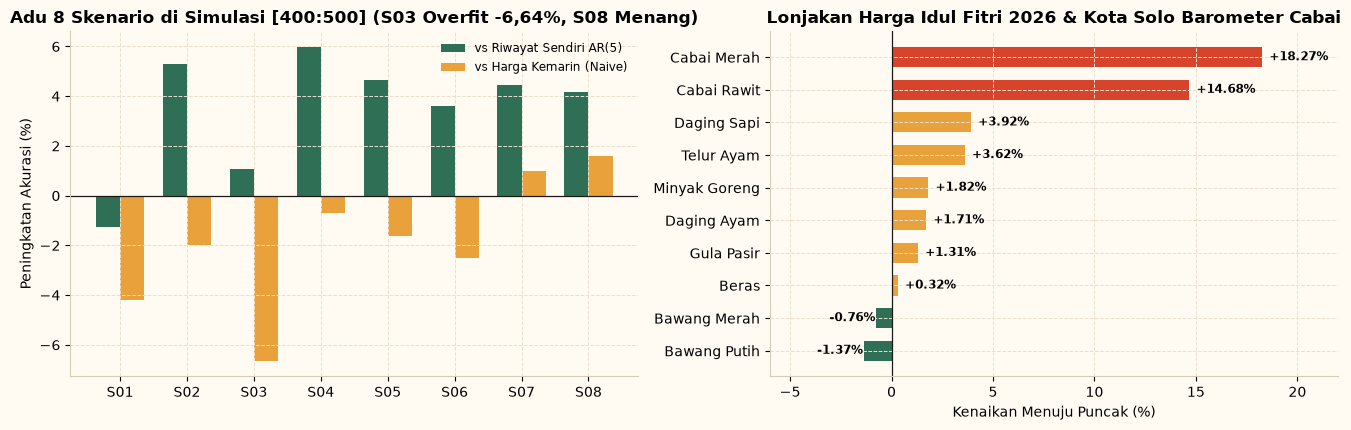

,commodity_name,n_cities,top_leader_city,top_leader_out_degree
0,Cabai Merah,105,Kota Surakarta (Solo),77
1,Bawang Merah,105,Kab. Mimika,80
2,Cabai Rawit,105,Kota Surakarta (Solo),75


In [5]:
scen_ts = pd.read_csv(ANALYSIS_DIR / "scenarios_timeseries_val.csv")
reg_df = pd.read_csv(ANALYSIS_DIR / "model_registry.csv")
eid_df = pd.read_csv(M2_DIR / "case_study_idul_fitri.csv")
city_sum = pd.read_csv(M2_DIR / "spatial_city_summary.csv")

display(scen_ts[["scenario_id", "lag_order", "ridge_alpha", "mean_skill_vs_ar_pct", "mean_skill_vs_naive_pct", "scenario_description"]])
display(reg_df[["model_id", "model_name", "duration_sec", "peak_ram_mb"]])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

x_s = np.arange(len(scen_ts))
axes[0].bar(x_s - 0.18, scen_ts["mean_skill_vs_ar_pct"], width=0.36, label="vs Riwayat Sendiri AR(5)", color="#2F6F55")
axes[0].bar(x_s + 0.18, scen_ts["mean_skill_vs_naive_pct"], width=0.36, label="vs Harga Kemarin (Naive)", color="#E9A23B")
axes[0].axhline(0, color="#1F1A17", linewidth=0.9)
axes[0].set_xticks(x_s)
axes[0].set_xticklabels(scen_ts["scenario_id"])
axes[0].set_ylabel("Peningkatan Akurasi (%)")
axes[0].set_title("Adu 8 Skenario di Simulasi [400:500] (S03 Overfit -6,64%, S08 Menang)", fontweight="bold")
axes[0].legend(frameon=False, fontsize=8.5)
axes[0].spines[["top", "right"]].set_visible(False)

eid_2026 = eid_df.loc[eid_df["event"] == "Idul_Fitri_2026"].sort_values("pct_change_to_peak", ascending=True)
ecols = ["#D8432B" if v >= 10 else ("#E9A23B" if v > 0 else "#2F6F55") for v in eid_2026["pct_change_to_peak"]]
bars_e = axes[1].barh(eid_2026["commodity_name"], eid_2026["pct_change_to_peak"], color=ecols, height=0.62)
for b, val in zip(bars_e, eid_2026["pct_change_to_peak"]):
    xpos = b.get_width() + 0.35 if val >= 0 else b.get_width() - 2.3
    axes[1].text(xpos, b.get_y() + b.get_height() / 2, f"{val:+.2f}%", va="center", fontsize=8.5, fontweight="bold")
axes[1].axvline(0, color="#1F1A17", linewidth=0.9)
axes[1].set_xlim(-6, 22)
axes[1].set_xlabel("Kenaikan Menuju Puncak (%)")
axes[1].set_title("Lonjakan Harga Idul Fitri 2026 & Kota Solo Barometer Cabai", fontweight="bold")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()
display(city_sum[["commodity_name", "n_cities", "top_leader_city", "top_leader_out_degree"]])

---
## 6. Ujian Dunia Nyata (`296` Hari Uji), Autopsi Error Kuliner, & Jembatan Sadar-Harga

Saat amplop ujian **`296` hari baru** dibuka dan dinilai oleh wasit *Diebold-Mariano*:
* **Jalur Harga:** `Domino ARX(5)` unggul sah di **Minyak Goreng (`+14,79%`, `p = 0,0002`)**, **Daging Sapi (`+10,00%` musiman / `+12,32%` raw)**, dan **Beras (`+6,62%`, `p = 0,0173`)**, sementara cabai dan bawang kalah oleh kejutan cuaca/panen lokal.
* **Jalur Kuliner:** *Isi Kulkasku* (`Conditional PMI`) menang sah **`45,50%`** vs popularitas **`40,88%`** (`CI 95%` terpisah). Sedangkan pada `25` soal substitusi (`Recall@5 = 24,0%`), autopsi `19` tebakan gagal membuktikan `10/19` sebenarnya menemukan **variasi bentuk/dialek dari bahan yang sama** (`santan dari kelapa`, `blok gula merah`, `miri`).

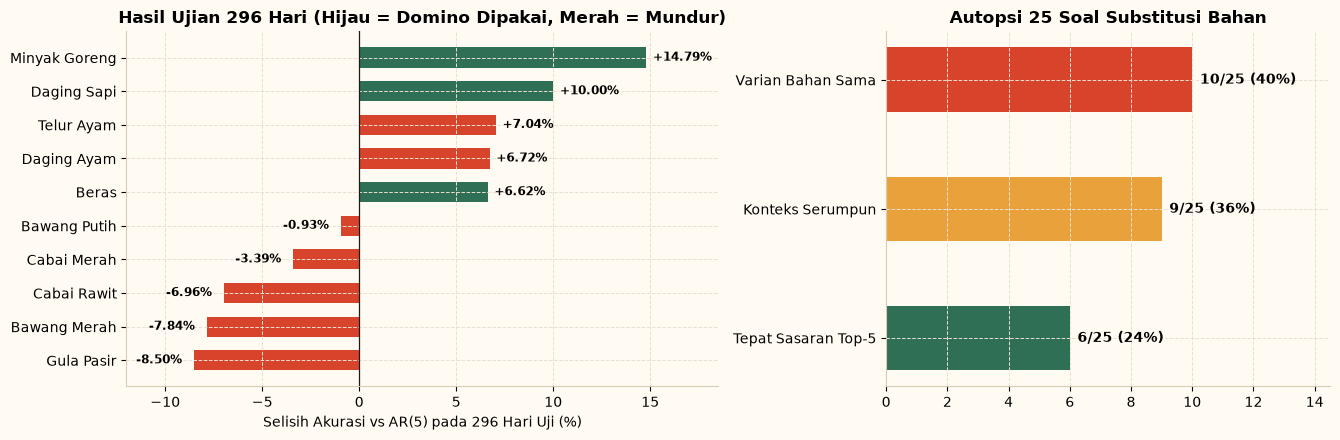

,target_ingredient,top_candidate,top_price_status,top_recipe_sub_score,top_combined_score
0,cabai merah keriting,cabai merah,mapped,0.7593,0.8284
1,cabai rawit,cabai rawit merah,mapped,0.8201,0.8707
2,bawang merah,ajinomoto,unmapped,0.5954,NaN
3,bawang putih,di,unmapped,0.5920,NaN
4,daging ayam,fillet dada ayam,unmapped,0.8001,NaN
5,telur ayam,telur kocok,unmapped,0.5727,NaN
6,minyak goreng,sy,unmapped,0.6078,NaN
7,gula pasir,kaldu bubuk non msg,unmapped,0.5181,NaN
8,kemiri,miri,unmapped,0.7400,NaN
9,santan,santan dari kelapa,unmapped,0.7763,NaN


In [6]:
rev_df = pd.read_csv(ANALYSIS_DIR / "model_review_decisions.csv").sort_values("skill_vs_ar_seasonal_pct", ascending=True)
err_df = pd.read_csv(ANALYSIS_DIR / "vp3_error_taxonomy.csv")
bridge_df = pd.read_csv(M4_DIR / "bridge_eval_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5), gridspec_kw={"width_ratios": [1.2, 0.9]})

rcols = ["#2F6F55" if "DEPLOY" in d else "#D8432B" for d in rev_df["review_decision"]]
bars_r = axes[0].barh(rev_df["commodity_name"], rev_df["skill_vs_ar_seasonal_pct"], color=rcols, height=0.6)
for b, val in zip(bars_r, rev_df["skill_vs_ar_seasonal_pct"]):
    xpos = b.get_width() + 0.35 if val >= 0 else b.get_width() - 3.0
    axes[0].text(xpos, b.get_y() + b.get_height() / 2, f"{val:+.2f}%", va="center", fontsize=8.5, fontweight="bold")
axes[0].axvline(0, color="#1F1A17", linewidth=0.9)
axes[0].set_xlim(-12, 18.5)
axes[0].set_xlabel("Selisih Akurasi vs AR(5) pada 296 Hari Uji (%)")
axes[0].set_title("Hasil Ujian 296 Hari (Hijau = Domino Dipakai, Merah = Mundur)", fontweight="bold")
axes[0].spines[["top", "right"]].set_visible(False)

counts = err_df["error_category"].value_counts()
labels = ["Tepat Sasaran Top-5" if "HIT" in k else ("Varian Bahan Sama" if "Varian" in k else "Konteks Serumpun") for k in counts.index]
ec = ["#2F6F55" if "Tepat" in l else ("#D8432B" if "Varian" in l else "#E9A23B") for l in labels]
bars_t = axes[1].barh(labels[::-1], counts.values[::-1], color=ec[::-1], height=0.5)
for b, v in zip(bars_t, counts.values[::-1]):
    axes[1].text(b.get_width() + 0.25, b.get_y() + b.get_height() / 2, f"{v}/25 ({int(round(100*v/25))}%)", va="center", fontweight="bold")
axes[1].set_xlim(0, 14.5)
axes[1].set_title("Autopsi 25 Soal Substitusi Bahan", fontweight="bold")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

display(bridge_df[["target_ingredient", "top_candidate", "top_price_status", "top_recipe_sub_score", "top_combined_score"]])

---
## 7. Tinjauan Akhir Model (*Go / Fallback*), Batasan Jujur, & Rencana Iterasi Ke-2

1. **Matriks Keputusan Produksi Per Komoditas:**
   * **Gunakan `Domino ARX(5) Ridge` (`3/10` bahan):** *Minyak Goreng*, *Daging Sapi*, dan *Beras*.
   * **Mundur ke `Univariate AR(5)` (`5/10` bahan):** *Cabai Merah*, *Cabai Rawit*, *Bawang Merah*, *Bawang Putih*, dan *Gula Pasir*.
   * **Mundur ke `Naive Last Price` (`2/10` bahan):** *Daging Ayam* dan *Telur Ayam*.
2. **Batasan Jujur:** Pola Granger mengukur keterdahuluan waktu (bukan sebab-akibat penuh rantai pasok), data harga resmi BI baru mencakup `10` komoditas (`1,05%` kosakata tetapi menjangkau **`27,74%`** pemakaian dapur tanpa satu pun harga buatan), dan satuan pasar `Rp/kg` berbeda dengan takaran resep.
3. **Peta Perbaikan Iterasi Ke-2:** (a) penyatuan frasa seinduk (*lemma deduplication*) seperti `'santan dari kelapa' → 'santan'` serta pemblokiran token 2 huruf (`'di'`, `'sy'`); (b) penambahan data curah hujan harian BMKG untuk cabai dan bawang; dan (c) audit kuartalan PIHPS.

In [7]:
display(rev_df[["commodity_name", "skill_vs_ar_raw_pct", "skill_vs_ar_seasonal_pct", "review_decision"]].sort_values("commodity_name"))
print("Notebook selesai dieksekusi dengan 0 error. Total puncak RAM pipeline M1-M4:", f"{reg_df['peak_ram_mb'].max():.2f} MB")

,commodity_name,skill_vs_ar_raw_pct,skill_vs_ar_seasonal_pct,review_decision
5,Bawang Merah,-12.69,-7.84,FALLBACK_KE_AR5_UNIVARIAT (Jangan Klaim Sinyal...
6,Bawang Putih,-2.04,-0.93,FALLBACK_KE_AR5_UNIVARIAT (Jangan Klaim Sinyal...
0,Beras,-3.01,6.62,DEPLOY_DOMINO_ARX5_SEASONAL (Menang Pasca-Kont...
7,Cabai Merah,-2.82,-3.39,FALLBACK_KE_AR5_UNIVARIAT (Jangan Klaim Sinyal...
8,Cabai Rawit,-6.85,-6.96,FALLBACK_KE_AR5_UNIVARIAT (Jangan Klaim Sinyal...
2,Daging Ayam,7.13,6.72,FALLBACK_KE_NAIVE_RANDOM_WALK (Sinyal Sangat S...
3,Daging Sapi,12.32,10.00,DEPLOY_DOMINO_ARX5 (Konsisten Menang di Raw & ...
1,Gula Pasir,-10.34,-8.50,FALLBACK_KE_AR5_UNIVARIAT (Jangan Klaim Sinyal...
9,Minyak Goreng,13.47,14.79,DEPLOY_DOMINO_ARX5_RAW (Menang di Return Mentah)
4,Telur Ayam,6.62,7.04,FALLBACK_KE_NAIVE_RANDOM_WALK (Sinyal Sangat S...


Notebook selesai dieksekusi dengan 0 error. Total puncak RAM pipeline M1-M4: 796.10 MB
